In [34]:
import pandas as pd
import matplotlib.pyplot as plt
from iris.config import PATHS
from iris.data.tiling import open_slide, thumbnail

df = pd.read_csv(PATHS.train_csv)
have = {p.stem for p in PATHS.images.glob("*.tiff")}
mine = df[df.image_id.isin(have)]
mine

,image_id,data_provider,isup_grade,gleason_score
58,01a5e35b1ae21f3cfbe100b4b6aef451,radboud,4,4+4
108,02e57c6acba29013ec3f1732ec373afe,radboud,2,3+4
158,0416b90e91acd8f71831c1723df3feb5,karolinska,1,3+3
192,051a2228aadbb0d44e61f8507114a4c0,radboud,4,5+3
233,061054331a952dd1c9df45c283d756b0,radboud,2,3+4
...,...,...,...,...
10442,fc5bf532ce01b1f52f38d5e87bebdb17,karolinska,1,3+3
10452,fc841358b1ae7c119b6224d0076046f4,radboud,1,3+3
10465,fcb4ae9ba7f26027fda8eb1d814a808d,karolinska,5,5+5
10475,fcf3f8be11a2d67438b6fd39ce1015a5,karolinska,1,3+3


In [2]:
row = mine[mine.isup_grade == 2].iloc[0]
slide = open_slide(PATHS.images / f"{row.image_id}.tiff")
print(row.data_provider, "| ISUP", row.isup_grade, "| Gleason", row.gleason_score)
print("levels:", slide.level_dimensions)

radboud | ISUP 2 | Gleason 3+4
levels: ((28160, 9216), (7040, 2304), (1760, 576))


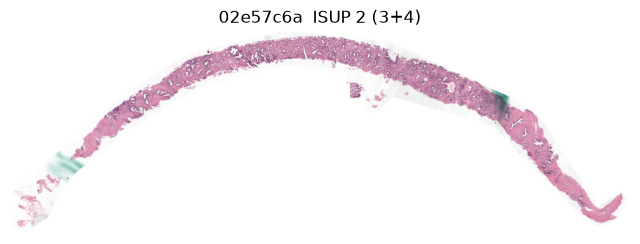

In [3]:
img = thumbnail(slide, 2)          # level 2 = the smallest zoom level
plt.figure(figsize=(8, 8))
plt.imshow(img)
plt.title(f"{row.image_id[:8]}  ISUP {row.isup_grade} ({row.gleason_score})")
plt.axis("off");

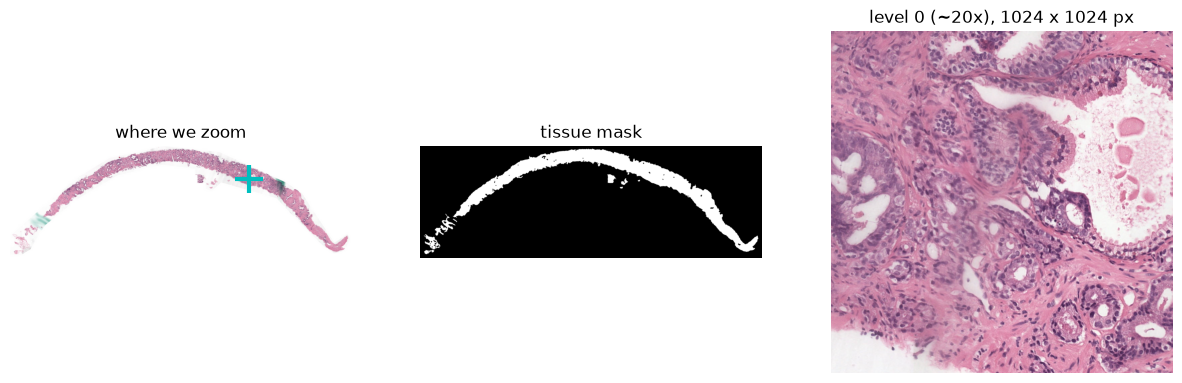

In [4]:
import numpy as np
from iris.data.tissue import tissue_mask

mask = tissue_mask(img)                 # True where there is tissue
ys, xs = np.nonzero(mask)
i = len(ys) // 2                        # a point in the middle of the tissue
down = slide.level_downsamples[2]       # level-2 pixel -> level-0 pixel
x0, y0 = int(xs[i] * down), int(ys[i] * down)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(img); ax[0].plot(xs[i], ys[i], "c+", ms=20, mew=3); ax[0].set_title("where we zoom")
ax[1].imshow(mask, cmap="gray"); ax[1].set_title("tissue mask")
ax[2].imshow(slide.read_region((x0 - 512, y0 - 512), 0, (1024, 1024)).convert("RGB"))
ax[2].set_title("level 0 (~20x), 1024 x 1024 px")
for a in ax: a.axis("off")


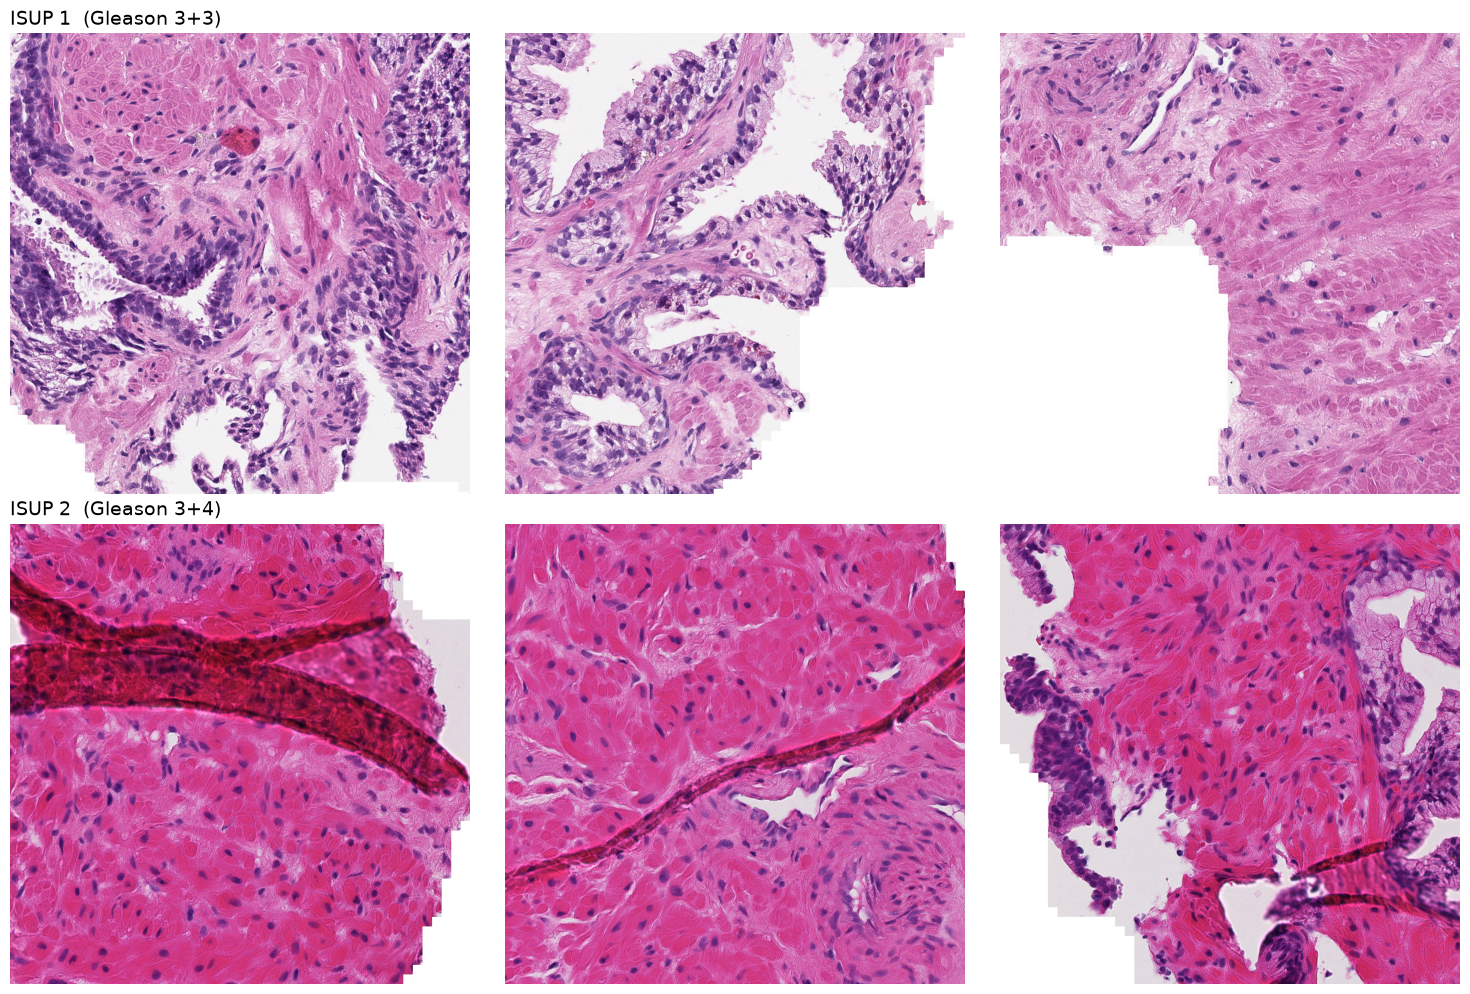

In [5]:
def zooms(row, n=3, size=768):
    """Open a slide and cut `n` full-resolution crops spread along its tissue."""
    s = open_slide(PATHS.images / f"{row.image_id}.tiff")
    small = thumbnail(s, 2)
    ys, xs = np.nonzero(tissue_mask(small))
    down = s.level_downsamples[2]
    crops = []
    for frac in np.linspace(0.2, 0.8, n):            # 20%, 50%, 80% along the tissue
        k = int(frac * len(ys))
        x0, y0 = int(xs[k] * down), int(ys[k] * down)
        crops.append(s.read_region((x0 - size // 2, y0 - size // 2), 0, (size, size)).convert("RGB"))
    return crops

# one GG1 and one GG2 slide from the SAME lab, so stain colour is comparable
lab = "karolinska"
gg1 = mine[(mine.isup_grade == 1) & (mine.data_provider == lab)].iloc[0]
gg2 = mine[(mine.isup_grade == 2) & (mine.data_provider == lab)].iloc[0]

fig, ax = plt.subplots(2, 3, figsize=(15, 10))
for r, row in enumerate([gg1, gg2]):
    for c, crop in enumerate(zooms(row)):
        ax[r, c].imshow(crop)
        ax[r, c].axis("off")
    ax[r, 0].set_title(f"ISUP {row.isup_grade}  (Gleason {row.gleason_score})", loc="left", fontsize=14)
plt.tight_layout()


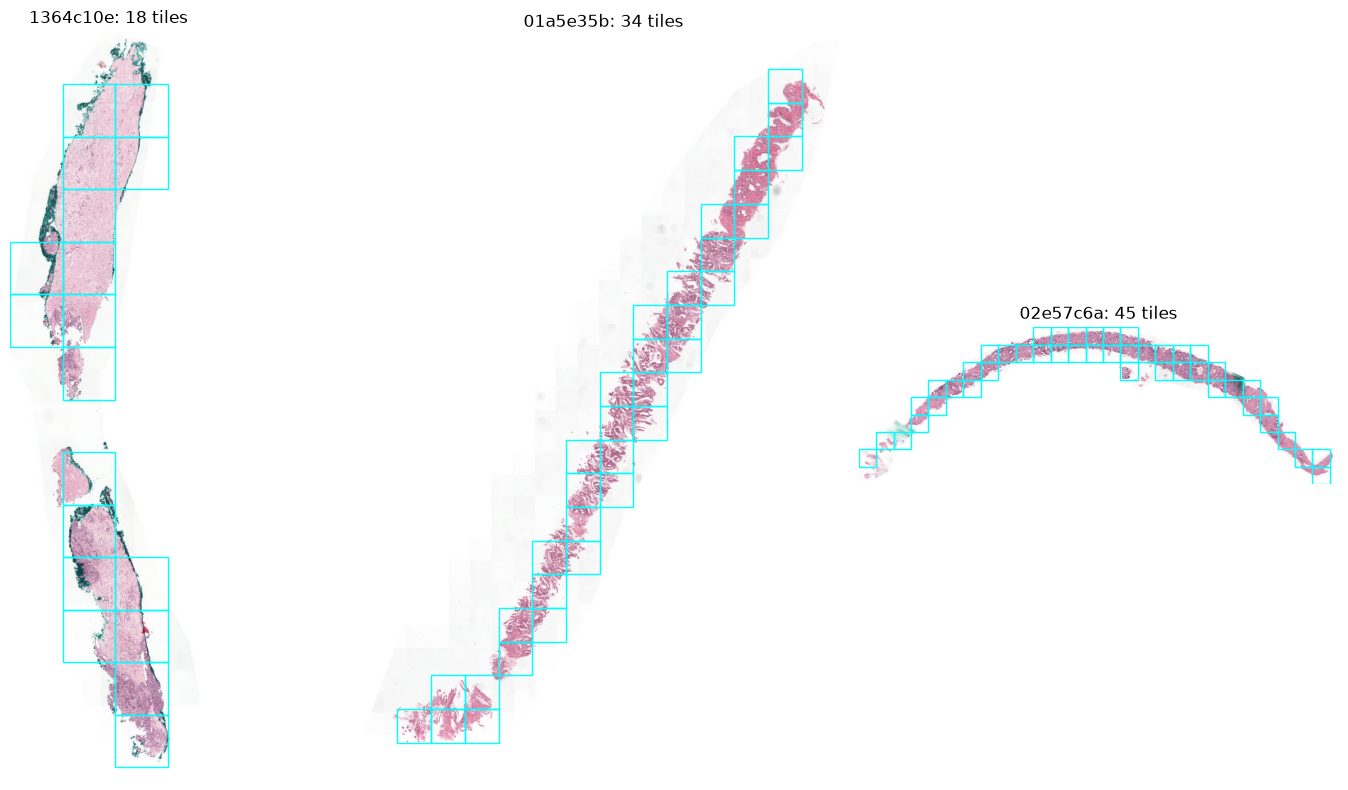

In [6]:
# Draw the tile grid on top of a slide thumbnail.
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from iris.config import PATHS, TileConfig
from iris.data.tiling import open_slide, thumbnail


def draw_grid(image_id, ax):
    slide = open_slide(PATHS.images / f"{image_id}.tiff")
    img = thumbnail(slide, 2)                       # the small level-2 picture we draw on

    coords = np.load(PATHS.coords / f"{image_id}.npy")
    scale = slide.level_downsamples[2]
    side0 = TileConfig().tile_size * slide.level_downsamples[1]
    w = side0 / scale

    ax.imshow(img)
    for x, y in coords:
        ax.add_patch(Rectangle((x / scale, y / scale), w, w,
                               fill=False, edgecolor="cyan", linewidth=1))
    ax.set_title(f"{image_id[:8]}: {len(coords)} tiles")
    ax.axis("off")


# the suspicious slide + two normal ones, side by side
ids = [next(PATHS.coords.glob("1364c10e*.npy")).stem]       # the 2-tile slide
ids += [p.stem for p in sorted(PATHS.coords.glob("*.npy")) if p.stem != ids[0]][:2]

fig, axes = plt.subplots(1, 3, figsize=(15, 8))
for image_id, ax in zip(ids, axes):
    draw_grid(image_id, ax)
plt.tight_layout()


In [7]:
import torch
from iris.config import PATHS

bag = torch.load(next(PATHS.features.glob("1364c10e*.pt")), weights_only=True)
f = bag["features"]
print("shape:", f.shape)
print("first tile, first 8 numbers:", f[0, :8].float())


shape: torch.Size([18, 1024])
first tile, first 8 numbers: tensor([0.7085, 0.6772, 0.1091, 0.0879, 0.3833, 0.0734, 0.1486, 0.0221])


In [10]:
df.gleason_score.value_counts()

gleason_score
3+3         2666
0+0         1925
3+4         1342
4+3         1243
4+4         1126
negative     967
4+5          849
5+4          248
5+5          127
3+5           80
5+3           43
Name: count, dtype: int64

In [35]:
pd.crosstab(df.gleason_score, df.data_provider)

data_provider,karolinska,radboud
gleason_score,,
0+0,1925,0
3+3,1814,852
3+4,667,675
3+5,13,67
4+3,318,925
4+4,466,660
4+5,208,641
5+3,2,41
5+4,27,221


In [48]:
expected = {
    "0+0": 0,
    "negative": 0,       
    "3+3": 1,
    "3+4": 2,
    "4+3": 3,
    "4+4": 4,
    "3+5": 4,
    "5+3": 4,
    "4+5": 5,
    "5+4": 5,
    "5+5": 5,
}

expected["negative"]


0

In [49]:
df["should_be"] = df.gleason_score.map(expected)
df[df.should_be != df.isup_grade]

,image_id,data_provider,isup_grade,gleason_score,should_be
7273,b0a92a74cb53899311acc30b7405e101,karolinska,2,4+3,3


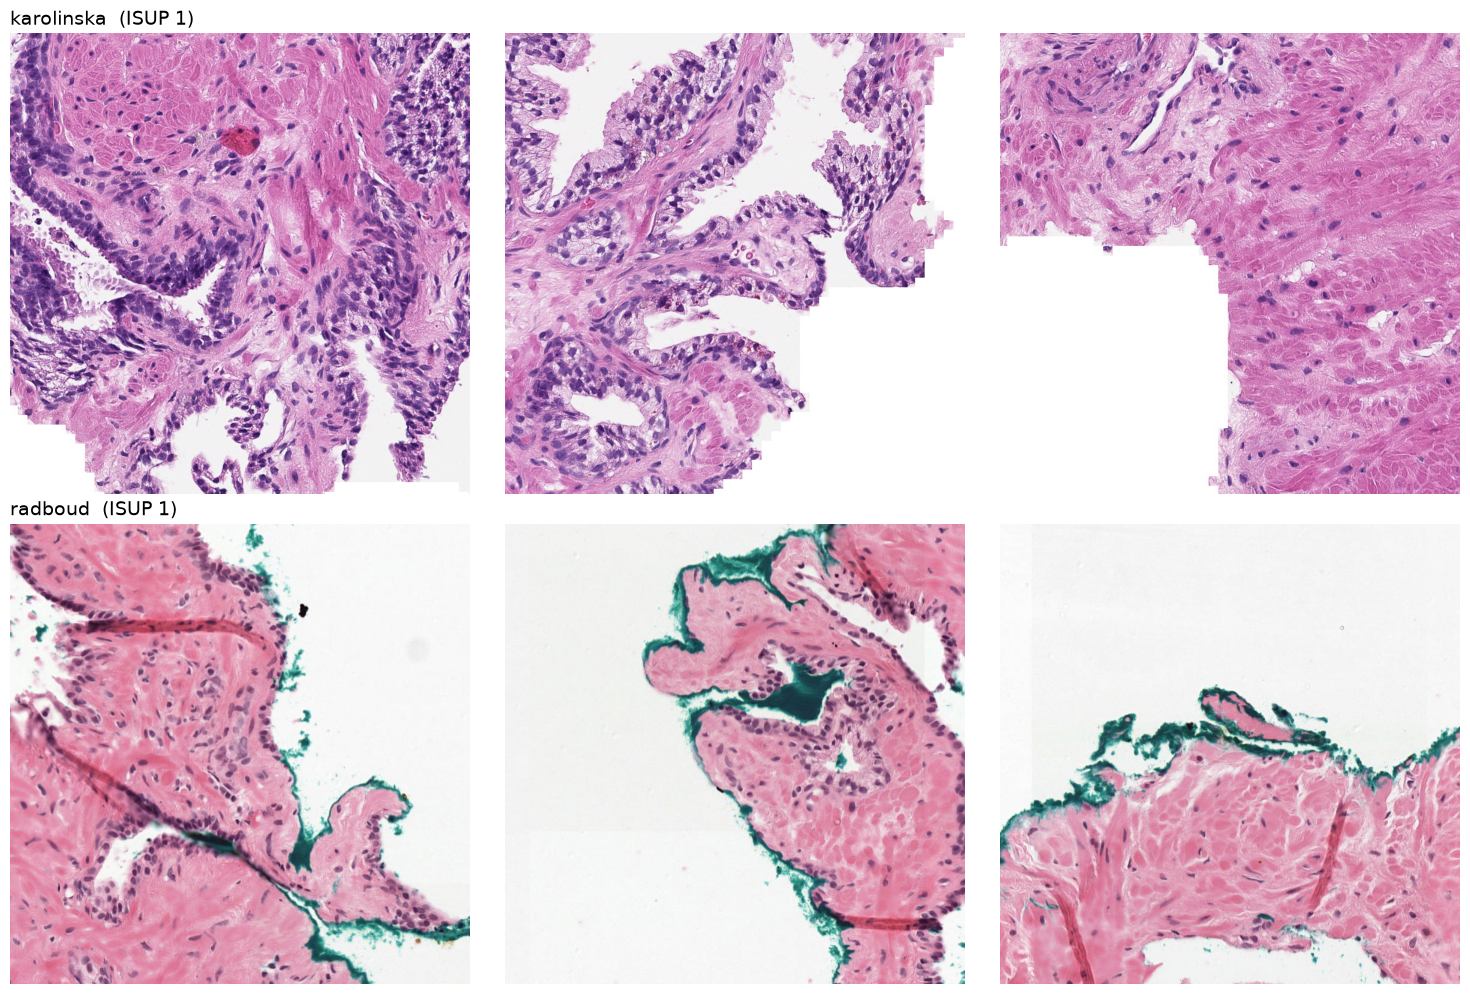

In [53]:
# One Karolinska slide and one Radboud slide with the SAME grade,
# so the only thing that changes between the two rows is the lab.
grade = 1
kar = mine[(mine.isup_grade == grade) & (mine.data_provider == "karolinska")].iloc[0]
rad = mine[(mine.isup_grade == grade) & (mine.data_provider == "radboud")].iloc[0]

fig, ax = plt.subplots(2, 3, figsize=(15, 10))
for r, row in enumerate([kar, rad]):
    for c, crop in enumerate(zooms(row)):
        ax[r, c].imshow(crop)
        ax[r, c].axis("off")
    ax[r, 0].set_title(f"{row.data_provider}  (ISUP {row.isup_grade})", loc="left", fontsize=14)
plt.tight_layout()


In [54]:
#Karolinska is deeper and more purple, with dark blue-purple nuclei.
#Radboud is brighter and more salmon-red, with paler nuclei.
#The green/cyan rim is ink, not tissue. Nothing in a prostate turns teal with H&E stain: H&E only gives pink and purple. So any green on a slide was put there by a person.
#It appears in one lab only. The Karolinska row has none. So green is a signature of where the slide came from, not of the cancer.
#A model can cheat with it. Radboud has many more high-grade slides than Karolinska (for example 4+5: 641 vs 208). A lazy model could learn "green rim → Radboud → probably a high grade" without looking at a single gland. That is called shortcut learning.

In [86]:
from iris.data.splits import make_test_split

split = make_test_split(df)
split.is_test.value_counts()

is_test
False    9022
True     1593
Name: count, dtype: int64

In [87]:
split[split.image_id.isin(have)].is_test.value_counts()

is_test
False    298
True       1
Name: count, dtype: int64

In [90]:
import torch

scores = torch.tensor([2.0, 2.0, 2.0])
torch.softmax(scores, dim=0)

tensor([0.3333, 0.3333, 0.3333])

In [91]:
from iris.models.abmil import GatedAttentionMIL

m = GatedAttentionMIL()
m.eval()
h = f.float()
h.shape

torch.Size([18, 1024])

In [92]:
h1 = m.fc(h)
h1.shape

torch.Size([18, 256])

In [102]:
t = torch.tanh(m.attn_V(h1))
g = torch.sigmoid(m.attn_U(h1))
a = m.attn_w(t * g)
t.shape, g.shape, a.shape

(torch.Size([18, 128]), torch.Size([18, 128]), torch.Size([18, 1]))

In [108]:
alpha = torch.softmax(a, dim=0)
alpha.shape, alpha.sum()

(torch.Size([18, 1]), tensor(1., grad_fn=<SumBackward0>))

In [116]:
z = (alpha * h1).sum(dim=0)
z.shape

torch.Size([256])

In [134]:
logits = m.classifier(z).unsqueeze(0)
logits.shape, logits

(torch.Size([1, 6]),
 tensor([[-0.2721, -0.0045, -0.1765,  0.2129,  0.0015, -0.1386]],
        grad_fn=<UnsqueezeBackward0>))

torch.Size([18, 256])